# 02 Modeling

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    fbeta_score,
    make_scorer,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.data_processor import (
    build_preprocessor,
    load_and_split_data,
)

In [2]:
RANDOM_STATE = 42

## Loading data and preprocessor

Functions from `data_processor.py` are used for retrieving split data for modeling and preprocessor for pipelining.

This is a classification problem, trying to predict **Attrition** from employees.

`stratify` is set to `True` since there's an imbalanced proportion (~84/16) for employees that have attrited.

In [3]:
X_train, X_test, y_train, y_test = load_and_split_data(
    "../data/raw/HR-Employee-Attrition.csv",
    target_col="Attrition",
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=True,
)

In [4]:
y_train.value_counts()

Attrition
False    986
True     190
Name: count, dtype: int64

In [5]:
y_test.value_counts()

Attrition
False    247
True      47
Name: count, dtype: int64

In [6]:
preprocessor = build_preprocessor()

## Baselining

For baselining, three classifiers are used:
1. `DummyClassifier`
2. `LogisticRegression`
3. `XGBClassifier`

For the three, class imbalance parameters are used, respectively:
1. `strategy="stratified"`
2. `class_weight="balanced"`
3. `scale_pos_weight`: This one is set to the ratio between negative examples and positive examples.

In [7]:
dummy_pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("clf", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)),
    ]
)

lr_baseline = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("clf", LogisticRegression(class_weight="balanced")),
    ]
)

scale_pos_weight = (
    y_train.value_counts(normalize=True).iloc[0]
    / y_train.value_counts(normalize=True).iloc[1]
)
xgb_baseline = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "clf",
            XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE),
        ),
    ]
)

In [8]:
%%time

f2_scorer = make_scorer(fbeta_score, beta=2)
scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "f2": f2_scorer,
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []

for model in (dummy_pipeline, lr_baseline, xgb_baseline):
    scores = cross_validate(
        model, X_train, y_train, scoring=scoring, cv=skf, return_train_score=True
    )
    scores["estimator"] = model.named_steps["clf"].__class__.__name__
    cv_results.append(scores)

CPU times: user 31.7 s, sys: 62.4 ms, total: 31.7 s
Wall time: 3.25 s


In [9]:
train_metrics = [
    "train_balanced_accuracy",
    "train_average_precision",
    "train_recall",
    "train_f1",
    "train_roc_auc",
    "train_f2",
]

test_metrics = [
    "test_balanced_accuracy",
    "test_average_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc",
    "test_f2",
]

for res in cv_results:
    print(f"=== Model: {res['estimator']} ===\n")

    for metric in train_metrics:
        scores = res[metric]
        print(f"{metric}:")
        print(f"  Mean: {scores.mean():.4f}")
        print(f"  Std:  {scores.std():.4f}")
        print(f"  Folds: {[round(s, 4) for s in scores]}")
        print()

    for metric in test_metrics:
        scores = res[metric]
        print(f"{metric}:")
        print(f"  Mean: {scores.mean():.4f}")
        print(f"  Std:  {scores.std():.4f}")
        print(f"  Folds: {[round(s, 4) for s in scores]}")
        print()

=== Model: DummyClassifier ===

train_balanced_accuracy:
  Mean: 0.4941
  Std:  0.0094
  Folds: [np.float64(0.4801), np.float64(0.4887), np.float64(0.4926), np.float64(0.5044), np.float64(0.5044)]

train_average_precision:
  Mean: 0.1603
  Std:  0.0022
  Folds: [np.float64(0.1574), np.float64(0.1588), np.float64(0.1597), np.float64(0.1628), np.float64(0.1628)]

train_recall:
  Mean: 0.1539
  Std:  0.0153
  Folds: [np.float64(0.1316), np.float64(0.1447), np.float64(0.1513), np.float64(0.1711), np.float64(0.1711)]

train_f1:
  Mean: 0.1529
  Std:  0.0154
  Folds: [np.float64(0.1303), np.float64(0.1438), np.float64(0.1503), np.float64(0.1699), np.float64(0.1699)]

train_roc_auc:
  Mean: 0.4941
  Std:  0.0094
  Folds: [np.float64(0.4801), np.float64(0.4887), np.float64(0.4926), np.float64(0.5044), np.float64(0.5044)]

train_f2:
  Mean: 0.1535
  Std:  0.0154
  Folds: [np.float64(0.1311), np.float64(0.1444), np.float64(0.1509), np.float64(0.1706), np.float64(0.1706)]

test_balanced_accuracy:

These are the results for the three classifiers with cross-validation:

**Test metrics**

| Model | Balanced Acc | Avg Precision | Recall | F1 | ROC AUC | F2 |
|---|---|---|---|---|---|---|
| DummyClassifier | 0.5054 ± 0.0172 | 0.1640 ± 0.0061 | 0.1579 ± 0.0288 | 0.1644 ± 0.0300 | 0.5054 ± 0.0172 | 0.1604 ± 0.0293 |
| LogisticRegression | 0.7458 ± 0.0234 | 0.6088 ± 0.0894 | 0.7421 ± 0.0510 | 0.4896 ± 0.0329 | 0.8282 ± 0.0310 | 0.6141 ± 0.0314 |
| XGBClassifier | 0.6907 ± 0.0346 | 0.5680 ± 0.0636 | 0.4211 ± 0.0725 | 0.5145 ± 0.0609 | 0.7981 ± 0.0388 | 0.4537 ± 0.0695 |

**Train metrics**

| Model | Balanced Acc | Avg Precision | Recall | F1 | ROC AUC | F2 |
|---|---|---|---|---|---|---|
| DummyClassifier | 0.4941 ± 0.0094 | 0.1603 ± 0.0022 | 0.1539 ± 0.0153 | 0.1529 ± 0.0154 | 0.4941 ± 0.0094 | 0.1535 ± 0.0154 |
| LogisticRegression | 0.7977 ± 0.0083 | 0.6862 ± 0.0136 | 0.8079 ± 0.0105 | 0.5554 ± 0.0138 | 0.8813 ± 0.0073 | 0.6835 ± 0.0109 |
| XGBClassifier | 1.0000 ± 0.0 | 1.0000 ± 0.0 | 1.0000 ± 0.0 | 1.0000 ± 0.0 | 1.0000 ± 0.0 | 1.0000 ± 0.0 |

Clearly, `LogisticRegression` shows better results for all the metrics except F1, which `XGBClassifier` obtained the best score (0.5145 vs 0.4896). `XGBClassifier` is overfitting, obtaining 1.0 in all the train metrics but worse results than `LogisticRegression` in test metrics.

## Hyperparameter tuning
### `LogisticRegression`
First, `LogisticRegression` will be optimized using `F2` scoring.

In [10]:
%%time
lr = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "clf",
            LogisticRegression(
                solver="lbfgs", max_iter=1000
            ),
        ),
    ]
)

param_grid = {
    "clf__C": np.logspace(-3, 3, 7).tolist(),
    "clf__class_weight": [None, "balanced"],
}

lr_gs = GridSearchCV(
    lr, param_grid=param_grid, scoring=f2_scorer, cv=skf, n_jobs=4, verbose=1
)
lr_gs.fit(X_train, y_train)

Fitting 5 folds for each of 14 candidates, totalling 70 fits


CPU times: user 415 ms, sys: 30.3 ms, total: 445 ms
Wall time: 3.71 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__C': [0.001, 0.01, ...], 'clf__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_ex

In [11]:
lr_gs.best_params_, lr_gs.best_score_

({'clf__C': 0.01, 'clf__class_weight': 'balanced'},
 np.float64(0.6218322907972605))

In [12]:
scores_lr = cross_validate(
    lr_gs.best_estimator_,
    X_train,
    y_train,
    scoring=scoring,
    cv=skf,
    return_train_score=True,
)
print("TRAIN: ", scores_lr["train_f2"].mean(), scores_lr["train_f2"].std())
print("TEST: ", scores_lr["test_f2"].mean(), scores_lr["test_f2"].std())

TRAIN:  0.646922879631484 0.008848187492142664
TEST:  0.6218322907972605 0.02721161999227089


Tuned model still preferred `class_weight="balanced"`, with a strong regularization `C=0.01`.

### C=0.01 vs C=0.1

Result from `C` hyperparameter will be evaluated using different `StratifiedKFold` with 20 seeds and compared with the lighter regularization `C=0.1`.

In [13]:
def make_lr(C):
    lr = Pipeline(
        [
            ("preprocessor", preprocessor),
            (
                "clf",
                LogisticRegression(
                    solver="lbfgs", C=C, max_iter=1000, class_weight="balanced"
                ),
            ),
        ]
    )
    
    return lr

In [14]:
Cs = (0.01, 0.1)
n_seeds = 20
f2 = np.empty((n_seeds, len(Cs), 5))

for seed in range(20):
    skf_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    for j, C in enumerate(Cs):
        scores = cross_validate(
            make_lr(C),
            X_train,
            y_train,
            scoring=f2_scorer,
            cv=skf_s,
        )
        f2[seed, j] = scores["test_score"]

d = f2[:, 0, :] - f2[:, 1, :]
d_seed = d.mean(axis=1)

print(f"Mean difference: {d_seed.mean():.4f} ± {d_seed.std(ddof=1):.4f}")
print(f"C=0.01 wins in: {(d_seed > 0).sum()} of {n_seeds} seeds")

Mean difference: -0.0135 ± 0.0086
C=0.01 wins in: 1 of 20 seeds


Although grid chose `C=0.01`, repeated cross-validation with 20 seeds showed that `C=0.1` performs better (mean difference: -0.0135 ± 0.0086, 0.01 wins in 1/20).

`C=0.1` is used.

In [15]:
best_lr = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "clf",
            LogisticRegression(
                solver="lbfgs", C=0.1, class_weight="balanced", max_iter=1000
            ),
        ),
    ]
)

In [16]:
scores_lr_v2 = cross_validate(
    best_lr,
    X_train,
    y_train,
    scoring=scoring,
    cv=skf,
    return_train_score=True,
)
print("TRAIN: ", scores_lr_v2["train_f2"].mean(), scores_lr_v2["train_f2"].std())
print("TEST: ", scores_lr_v2["test_f2"].mean(), scores_lr_v2["test_f2"].std())

TRAIN:  0.6791458520851279 0.010379837093201052
TEST:  0.6133924598297409 0.0435603406994035


### `XGBClassifier`

In [17]:
%%time
xgb = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("clf", XGBClassifier(random_state=RANDOM_STATE)),
    ]
)

param_distribs = {
    "clf__max_depth": np.arange(2, 11, 1).tolist(),
    "clf__min_child_weight": np.arange(0, 8, 1).tolist(),
    "clf__subsample": np.linspace(0.5, 1.0, 6).tolist(),
    "clf__colsample_bytree": np.linspace(0.5, 1.0, 6).tolist(),
    "clf__reg_alpha": [0, 0.01, 0.1, 1, 5, 10, 50],
    "clf__reg_lambda": [0, 0.01, 0.1, 1, 5, 10, 50],
    "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "clf__n_estimators": [200, 400, 600, 800],
}

xgb_rs = RandomizedSearchCV(
    xgb,
    param_distributions=param_distribs,
    n_iter=80,
    scoring=f2_scorer,
    cv=skf,
    n_jobs=4,
    verbose=1,
    random_state=RANDOM_STATE,
)
xgb_rs.fit(X_train, y_train)

Fitting 5 folds for each of 80 candidates, totalling 400 fits
CPU times: user 6.34 s, sys: 127 ms, total: 6.47 s
Wall time: 29.9 s


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'clf__colsample_bytree': [0.5, 0.6, ...], 'clf__learning_rate': [0.01, 0.03, ...], 'clf__max_depth': [2, 3, ...], 'clf__min_child_weight': [0, 1, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",80
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum

In [18]:
xgb_rs.best_params_, xgb_rs.best_score_

({'clf__subsample': 0.9,
  'clf__reg_lambda': 0.01,
  'clf__reg_alpha': 1,
  'clf__n_estimators': 800,
  'clf__min_child_weight': 5,
  'clf__max_depth': 2,
  'clf__learning_rate': 0.1,
  'clf__colsample_bytree': 0.9},
 np.float64(0.48323780794369026))

In [19]:
scores_xgb = cross_validate(
    xgb_rs.best_estimator_,
    X_train,
    y_train,
    scoring=scoring,
    cv=skf,
    return_train_score=True,
)
print("TRAIN: ", scores_xgb["train_f2"].mean(), scores_xgb["train_f2"].std())
print("TEST: ", scores_xgb["test_f2"].mean(), scores_xgb["test_f2"].std())

TRAIN:  0.9244133286495988 0.008598886938532817
TEST:  0.48323780794369026 0.06701009942457077


Using `RandomizedSearchCV`, two hyperparameters are at the boundaries of the search space: `max_depth` and `n_estimators`. These will be used in a `GridSearchCV` with other hyperparameters set to the best results found in `RandomizedSearchCV`.

In [20]:
best_subsample = xgb_rs.best_params_["clf__subsample"]
best_reg_lambda = xgb_rs.best_params_["clf__reg_lambda"]
best_reg_alpha = xgb_rs.best_params_["clf__reg_alpha"]
best_min_child_weight = xgb_rs.best_params_["clf__min_child_weight"]
best_learning_rate = xgb_rs.best_params_["clf__learning_rate"]
best_colsample_bytree = xgb_rs.best_params_["clf__colsample_bytree"]

In [21]:
%%time
xgb_v2 = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "clf",
            XGBClassifier(
                random_state=RANDOM_STATE,
                subsample=best_subsample,
                reg_lambda=best_reg_lambda,
                reg_alpha=best_reg_alpha,
                min_child_weight=best_min_child_weight,
                learning_rate=best_learning_rate,
                colsample_bytree=best_colsample_bytree,
            ),
        ),
    ]
)

param_grid = {
    "clf__max_depth": np.arange(1, 6, 1).tolist(),
    "clf__n_estimators": [800, 1000, 1200, 1400],
}

xgb_gs = GridSearchCV(
    xgb_v2, param_grid=param_grid, scoring=f2_scorer, cv=skf, n_jobs=4, verbose=1
)
xgb_gs.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
CPU times: user 4.33 s, sys: 51.2 ms, total: 4.38 s
Wall time: 11.9 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__max_depth': [1, 2, ...], 'clf__n_estimators': [800, 1000, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_e

In [22]:
xgb_gs.best_params_, xgb_gs.best_score_

({'clf__max_depth': 1, 'clf__n_estimators': 1400},
 np.float64(0.511690574797691))

In [23]:
scores_xgb_v2 = cross_validate(
    xgb_gs.best_estimator_,
    X_train,
    y_train,
    scoring=scoring,
    cv=skf,
    return_train_score=True,
)
print("TRAIN: ", scores_xgb_v2["train_f2"].mean(), scores_xgb_v2["train_f2"].std())
print("TEST: ", scores_xgb_v2["test_f2"].mean(), scores_xgb_v2["test_f2"].std())

TRAIN:  0.7004462597475849 0.020140867287320133
TEST:  0.511690574797691 0.0540849596558996


F2 score improved ~0.0285 after `GridSearchCV` and showed less overfitting (train/test F2 gap ~0.19).

### `RandomForest`

An additional classifier is going to be used for analysis; only `class_weight="balanced"` hyperparameter is used for fair comparison.

In [24]:
rf = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "clf",
            RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
        ),
    ]
)

scores_rf = cross_validate(
    rf, X_train, y_train, scoring=scoring, cv=skf, return_train_score=True
)
print("TRAIN: ", scores_rf["train_f2"].mean(), scores_rf["train_f2"].std())
print("TEST: ", scores_rf["test_f2"].mean(), scores_rf["test_f2"].std())

TRAIN:  0.9992115637319318 0.0006437555171571866
TEST:  0.35682523152452855 0.10114275015175724


In [25]:
%%time
rf_v2 = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("clf", RandomForestClassifier(criterion="gini", random_state=RANDOM_STATE)),
    ]
)

param_distribs = {
    "clf__n_estimators": [100, 300, 500, 700, 900, 1000],
    "clf__max_depth": np.arange(1, 10, 1).tolist(),
    "clf__max_features": ["sqrt", "log2", None],
    "clf__min_samples_split": np.arange(2, 10, 1).tolist(),
    "clf__class_weight": [None, "balanced", "balanced_subsample"],
}

rf_rs = RandomizedSearchCV(
    rf_v2,
    param_distributions=param_distribs,
    n_iter=80,
    scoring=f2_scorer,
    cv=skf,
    n_jobs=4,
    verbose=1,
    random_state=RANDOM_STATE,
)
rf_rs.fit(X_train, y_train)

Fitting 5 folds for each of 80 candidates, totalling 400 fits
CPU times: user 3.35 s, sys: 215 ms, total: 3.57 s
Wall time: 2min 49s


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'clf__class_weight': [None, 'balanced', ...], 'clf__max_depth': [1, 2, ...], 'clf__max_features': ['sqrt', 'log2', ...], 'clf__min_samples_split': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",80
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than m

In [26]:
rf_rs.best_params_, rf_rs.best_score_

({'clf__n_estimators': 1000,
  'clf__min_samples_split': 7,
  'clf__max_features': 'log2',
  'clf__max_depth': 4,
  'clf__class_weight': 'balanced'},
 np.float64(0.5164828576184103))

In [27]:
scores_rf_v2 = cross_validate(
    rf_rs.best_estimator_,
    X_train,
    y_train,
    scoring=scoring,
    cv=skf,
    return_train_score=True,
)
print("TRAIN: ", scores_rf_v2["train_f2"].mean(), scores_rf_v2["train_f2"].std())
print("TEST: ", scores_rf_v2["test_f2"].mean(), scores_rf_v2["test_f2"].std())

TRAIN:  0.7361972346412538 0.01211724916079071
TEST:  0.5164828576184103 0.04997252934841406


`RandomForest` has a higher score than `XGBClassifier`  (0.5165 vs 0.5117) but more overfitting:
- `RandomForest` train/test gap: ~0.22
- `XGBClassifier` train/test gap: ~0.19

Tuned `RandomForest` has a negligible advantage over `XGBClassifier` (~0.005) with a similar std (RF: ~0.0500, XGB: ~0.0541). However, it has a larger train/test gap (RF: ~0.22, XGB: ~0.19).

## Model comparison

With all models' results from cross-validation, same metrics from baselining will be used for analysis.

In [28]:
final_cv_results = {
    "LogisticRegression": scores_lr_v2,
    "XGBClassifier": scores_xgb,
    "XGBClassifier v2": scores_xgb_v2,
    "RandomForest": scores_rf,
    "RandomForest v2": scores_rf_v2,
}

for name, res in final_cv_results.items():
    print(f"=== Model: {name} ===\n")

    for metric in train_metrics:
        results = res[metric]
        print(f"{metric}:")
        print(f"  Mean: {results.mean():.4f}")
        print(f"  Std:  {results.std():.4f}")
        print(f"  Folds: {[round(s, 4) for s in results]}")
        print()

    for metric in test_metrics:
        results = res[metric]
        print(f"{metric}:")
        print(f"  Mean: {results.mean():.4f}")
        print(f"  Std:  {results.std():.4f}")
        print(f"  Folds: {[round(s, 4) for s in results]}")
        print()

=== Model: LogisticRegression ===

train_balanced_accuracy:
  Mean: 0.7945
  Std:  0.0082
  Folds: [np.float64(0.7883), np.float64(0.8083), np.float64(0.7917), np.float64(0.7853), np.float64(0.7988)]

train_average_precision:
  Mean: 0.6944
  Std:  0.0140
  Folds: [np.float64(0.6919), np.float64(0.7125), np.float64(0.6857), np.float64(0.6744), np.float64(0.7075)]

train_recall:
  Mean: 0.8039
  Std:  0.0049
  Folds: [np.float64(0.7961), np.float64(0.8092), np.float64(0.8026), np.float64(0.8026), np.float64(0.8092)]

train_f1:
  Mean: 0.5510
  Std:  0.0145
  Folds: [np.float64(0.5426), np.float64(0.5761), np.float64(0.5459), np.float64(0.5339), np.float64(0.5566)]

train_roc_auc:
  Mean: 0.8761
  Std:  0.0074
  Folds: [np.float64(0.8807), np.float64(0.8814), np.float64(0.873), np.float64(0.8628), np.float64(0.8825)]

train_f2:
  Mean: 0.6791
  Std:  0.0104
  Folds: [np.float64(0.6707), np.float64(0.6965), np.float64(0.6755), np.float64(0.6681), np.float64(0.6849)]

test_balanced_accurac

These are the results for the five tuned models with cross-validation:

**Test metrics**

| Model | Balanced Acc | Avg Precision | Recall | F1 | ROC AUC | F2 |
|---|---|---|---|---|---|---|
| LogisticRegression | 0.7458 ± 0.0300 | 0.6301 ± 0.0661 | 0.7421 ± 0.0714 | 0.4884 ± 0.0329 | 0.8318 ± 0.0304 | 0.6134 ± 0.0436 |
| XGBClassifier | 0.7055 ± 0.0322 | 0.6021 ± 0.0383 | 0.4526 ± 0.0714 | 0.5393 ± 0.0559 | 0.8168 ± 0.0189 | 0.4832 ± 0.0670 |
| XGBClassifier v2 | 0.7207 ± 0.0275 | 0.6485 ± 0.0539 | 0.4789 ± 0.0562 | 0.5715 ± 0.0525 | 0.8407 ± 0.0186 | 0.5117 ± 0.0541 |
| RandomForest | 0.6429 ± 0.0486 | 0.5452 ± 0.0909 | 0.3263 ± 0.1021 | 0.4186 ± 0.1012 | 0.8003 ± 0.0385 | 0.3568 ± 0.1011 |
| RandomForest v2 | 0.7027 ± 0.0258 | 0.5362 ± 0.0635 | 0.5474 ± 0.0694 | 0.4790 ± 0.0364 | 0.7921 ± 0.0248 | 0.5165 ± 0.0500 |

**Train metrics**

| Model | Balanced Acc | Avg Precision | Recall | F1 | ROC AUC | F2 |
|---|---|---|---|---|---|---|
| LogisticRegression | 0.7945 ± 0.0082 | 0.6944 ± 0.0140 | 0.8039 ± 0.0049 | 0.5510 ± 0.0145 | 0.8761 ± 0.0074 | 0.6791 ± 0.0104 |
| XGBClassifier | 0.9537 ± 0.0052 | 0.9929 ± 0.0017 | 0.9079 ± 0.0110 | 0.9504 ± 0.0050 | 0.9980 ± 0.0009 | 0.9244 ± 0.0086 |
| XGBClassifier v2 | 0.8251 ± 0.0111 | 0.8734 ± 0.0092 | 0.6605 ± 0.0219 | 0.7704 ± 0.0168 | 0.9475 ± 0.0018 | 0.7004 ± 0.0201 |
| RandomForest | 0.9996 ± 0.0003 | 1.0000 ± 0.0 | 1.0000 ± 0.0 | 0.9980 ± 0.0016 | 1.0000 ± 0.0 | 0.9992 ± 0.0006 |
| RandomForest v2 | 0.8393 ± 0.0077 | 0.7333 ± 0.0091 | 0.7947 ± 0.0163 | 0.6631 ± 0.0111 | 0.9101 ± 0.0059 | 0.7362 ± 0.0121 |

F2 and recall metrics are very important for this case. False negatives are expensive, since not flagging potential attritions will be a waste in training and resources in these risky employees.

`LogisticRegression` shows better results for these metrics (Recall=0.7421, F2=0.6134), with a small gap between train and test metrics (0.06, 0.07), indicating good generalization. Its test Recall varies more across folds (std 0.0714) than before, so the estimate is less stable than it looked.

`XGBClassifier` shows some improvements after second tuning (v2):
- Recall: +0.0263 (0.4526 → 0.4789)
- F2: +0.0285 (0.4832 → 0.5117)

And this comes with a narrower train/test gap:
- Recall gap: 0.4553 → 0.1816
- F2 gap: 0.4412 → 0.1887

`RandomForest` shows that tuning substantially reduced overfitting and improved performance:
- Recall gap: 0.6737 → 0.2473
- F2 gap: 0.6424 → 0.2197
- Test Recall: 0.3263 → 0.5474
- Test F2: 0.3568 → 0.5165

Despite this improvement, `LogisticRegression` remains the best-performing model for this use case, with the highest test Recall (0.7421) and F2 (0.6134) and the smallest train/test gap among the models, indicating the most reliable generalization to unseen data. Note that `XGBClassifier v2` is slightly better in Avg Precision, ROC AUC and F1, but the differences in AP and ROC AUC are within one standard deviation, and its Recall and F2 are far lower, which are the metrics that matter most here.

## Feature importance

Features from data will be sorted by their coefficient, according to the fitted model.

In [29]:
final_model = best_lr
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Age','BusinessTravel','DailyRate',...,'YearsSinceLastPromotion', 'YearsWithCurrManager','IsMale']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('numerical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

In [30]:
pd.DataFrame(
    {
        "feat": best_lr.named_steps["preprocessor"].get_feature_names_out(),
        "coef": best_lr.named_steps["clf"].coef_.flatten(),
    }
).sort_values(by="coef", ascending=False)

,feat,coef
45,remainder__OverTime,1.243645
0,ordinal__BusinessTravel,0.676044
35,nominal__JobRole_Laboratory Technician,0.675427
41,nominal__JobRole_Sales Representative,0.428674
22,numerical__YearsSinceLastPromotion,0.419741
12,numerical__NumCompaniesWorked,0.378798
44,nominal__MaritalStatus_Single,0.372483
26,nominal__Department_Sales,0.309188
3,numerical__DistanceFromHome,0.277658
32,nominal__EducationField_Technical Degree,0.261276


**Top factors increasing attrition risk**

- `OverTime` (+1.24): Strongest predictor; working overtime increases risk.
- `BusinessTravel` (+0.68): More frequent travel is associated with higher attrition.
- `JobRole_Laboratory Technician` (+0.68): This role shows higher attrition propensity than others.
- `YearsSinceLastPromotion` (+0.42): Longer time without promotion increases risk.
- `NumCompaniesWorked` (+0.38): A history of more employers correlates with attrition risk.
- `MaritalStatus_Single` (+0.37): Single employees show higher risk.

**Top factors decreasing attrition risk**

- `TotalWorkingYears` (-0.38): Greater seniority reduces attrition risk.
- `YearsWithCurrManager` (-0.37): Employees with more time with same manager are less likely to attrition.
- `EnvironmentSatisfaction` (-0.36) & `JobSatisfaction` (-0.34): Employees with higher satisfaction reduce risk.

**No contribution (coefficients near 0, negligible effect on predictions)**

- `Education` (-0.006)
- `Department_Human Resources` (0.002)
- `MonthlyRate` (0.024)
- `JobRole_Manager` (0.009)

## Decision threshold tuning

For this section, the decision threshold for the final model is tuned. Although F2 was used as the metric for cross-validation and hyperparameter search, a separate threshold must still be tuned for predicting attrition, since failing to identify employees who are likely to leave is more costly for the company than flagging employees who would have stayed.

In [31]:
thresholds = np.linspace(0.05, 0.95, 91)
f2_runs, bests = [], []

for seed in range(10):
    skf_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    oof_proba = cross_val_predict(
        final_model, X_train, y_train, cv=skf_s, method="predict_proba"
    )[:, 1]
    f2_i = [fbeta_score(y_train, oof_proba >= t, beta=2) for t in thresholds]
    f2_runs.append(f2_i)
    bests.append(thresholds[int(np.argmax(f2_i))])

In [32]:
f2_mean = np.mean(f2_runs, axis=0)
best = thresholds[int(np.argmax(f2_mean))]

print("bests:", bests)
print(f"best over F2 mean: {best:.2f} (std bests: {np.std(bests):.3f})")

bests: [np.float64(0.5399999999999999), np.float64(0.57), np.float64(0.4699999999999999), np.float64(0.5399999999999999), np.float64(0.5499999999999999), np.float64(0.5299999999999999), np.float64(0.5499999999999999), np.float64(0.5599999999999999), np.float64(0.48999999999999994), np.float64(0.49999999999999994)]
best over F2 mean: 0.55 (std bests: 0.031)


In [33]:
i50 = int(np.argmin(np.abs(thresholds - 0.50)))
i55 = int(np.argmin(np.abs(thresholds - 0.55)))

f2_arr = np.array(f2_runs)
f2_50, f2_55 = f2_arr[:, i50], f2_arr[:, i55]
diff = f2_55 - f2_50

print(f"F2 @0.50: {f2_50.mean():.4f} ± {f2_50.std():.4f}")
print(f"F2 @0.55: {f2_55.mean():.4f} ± {f2_55.std():.4f}")
print(f"diff (0.55 - 0.50): {diff.mean():.4f} ± {diff.std():.4f}")
print(f"seeds where 0.55 wins: {(diff > 0).sum()}/10")

F2 @0.50: 0.6325 ± 0.0081
F2 @0.55: 0.6382 ± 0.0115
diff (0.55 - 0.50): 0.0057 ± 0.0089
seeds where 0.55 wins: 8/10


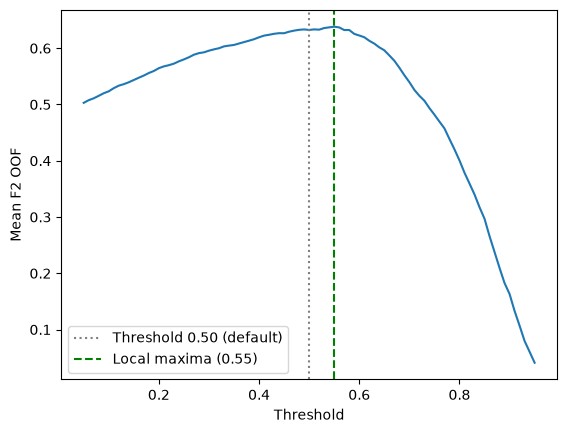

In [34]:
plt.plot(thresholds, f2_arr.mean(axis=0))
plt.xlabel("Threshold")
plt.ylabel("Mean F2 OOF")
plt.axvline(0.50, ls=":", color="gray", label="Threshold 0.50 (default)")
plt.axvline(0.55, ls="--", color="green", label="Local maxima (0.55)")
plt.legend();

There is an increase in Mean F2 OOF when using the new threshold of 0.55. However, the difference is marginal: 0.0057 ± 0.0089. Even though 0.55 won in 8 of the 10 seeds and is the global maximum in the plot threshold vs. Mean F2 OOF, **threshold 0.50 will be kept because of the negligible difference in F2 score compared with the tuned threshold**.

## Final test

In [35]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "average_precision": average_precision_score(y_test, y_proba),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "f2": fbeta_score(y_test, y_pred, beta=2),
    "roc_auc": roc_auc_score(y_test, y_proba),
}

In [36]:
for name, value in test_metrics.items():
    print(f"{name}: {value:.4f}")

balanced_accuracy: 0.7205
average_precision: 0.5730
recall: 0.6596
f1: 0.4697
f2: 0.5678
roc_auc: 0.8082


**LogisticRegression: CV vs final test**

| Metric | CV Test (mean ± std) | Final Test | Difference |
|---|---|---|---|
| Balanced Acc | 0.7458 ± 0.0300 | 0.7205 | -0.0253 |
| Avg Precision | 0.6301 ± 0.0661 | 0.5730 | -0.0571 |
| Recall | 0.7421 ± 0.0714 | 0.6596 | -0.0825 |
| F1 | 0.4884 ± 0.0329 | 0.4697 | -0.0187 |
| ROC AUC | 0.8318 ± 0.0304 | 0.8082 | -0.0236 |
| F2 | 0.6134 ± 0.0436 | 0.5678 | -0.0456 |

Final test performance is below the cross-validation estimate on every metric. No metric falls more than two standard deviations below it. The standard deviations come from five folds, and the test set is a single small sample with about 47 positive cases. Hyperparameters were selected using the same CV folds, so a small optimistic bias is expected.

## Model export

> The final and training and model export is in src/model_trainer.py.